## 1. Objectives

- Inspect and validate the prepared feature dataset.
- Explore statistical features and class patterns.
- Establish a reproducible stratified train/test baseline.
- Train and tune Random Forest and Support Vector Machine (SVM) using training data only.
- Evaluate both models on the same held-out test set.
- Interpret Random Forest feature importance.
- Select a model using measured test metrics, then export it with a configuration file for later backend integration.

> **Validation limitation:** the CSV has no recording IDs or chronological window indices. Random stratification is useful as an initial baseline, but windows from the same original recording may appear in both partitions. Therefore, test performance cannot be claimed to represent performance on completely unseen physical recordings. A recording-aware split should be used when provenance becomes available.

## 2. Environment, imports, and configuration



In [4]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from joblib import dump, load
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance

SEED = 42
np.random.seed(SEED)

FEATURE_COLUMNS = [
    "max", "min", "mean", "sd", "rms",
    "skewness", "kurtosis", "crest", "form"
]
TARGET_COLUMN = "fault"

SAMPLING_FREQUENCY_HZ = 48_000
WINDOW_SIZE_SAMPLES = 2_048

EXPECTED_CLASSES = [
    "Ball_007_1", "Ball_014_1", "Ball_021_1",
    "IR_007_1", "IR_014_1", "IR_021_1",
    "OR_007_6_1", "OR_014_6_1", "OR_021_6_1",
    "Normal_1"
]

# Locate the project folder based on the notebook's current working directory.
cwd = Path.cwd()
candidate_roots = [cwd, cwd.parent, cwd.parent.parent]
PROJECT_ROOT = next(
    (p for p in candidate_roots if (p / "feature_time_48k_2048_load1.csv").exists()),
    None
)
if PROJECT_ROOT is None:
    # Typical layout: notebook is in Motor/notebooks/
    PROJECT_ROOT = cwd.parent if cwd.name.lower() == "notebooks" else cwd

DATASET_FILENAME = "feature_time_48k_2048_load_1.csv"
DATASET_PATH = PROJECT_ROOT / DATASET_FILENAME
MODEL_DIR = PROJECT_ROOT / "models"

print("Working directory:", cwd)
print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATASET_PATH)
print("Model output directory:", MODEL_DIR)

Working directory: c:\Users\User\Desktop\Motor\notebooks
Project root: c:\Users\User\Desktop\Motor
Dataset path: c:\Users\User\Desktop\Motor\feature_time_48k_2048_load_1.csv
Model output directory: c:\Users\User\Desktop\Motor\models


## 3. Load and inspect the dataset

In [7]:

if not DATASET_PATH.exists():
    
    alternatives = [
        cwd / DATASET_FILENAME,
        cwd / "Motor" / DATASET_FILENAME,
        cwd.parent / "Motor" / DATASET_FILENAME,
        cwd.parent / DATASET_FILENAME,
    ]
    DATASET_PATH = next((p for p in alternatives if p.exists()), DATASET_PATH)

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Could not locate {DATASET_FILENAME}. Place it in the project folder "
        f"or adjust DATASET_PATH. Checked relative locations from {cwd}."
    )
df = pd.read_csv(DATASET_PATH)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
display(df.head())
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))
print("\nDuplicate rows:", df.duplicated().sum())
print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Shape: (2300, 10)

Columns:
['max', 'min', 'mean', 'sd', 'rms', 'skewness', 'kurtosis', 'crest', 'form', 'fault']


,max,min,mean,sd,rms,skewness,kurtosis,crest,form,fault
0,0.35986,-0.41890,0.017840,0.122746,0.124006,-0.118571,-0.042219,2.901946,6.950855,Ball_007_1
1,0.46772,-0.36111,0.022255,0.132488,0.134312,0.174699,-0.081548,3.482334,6.035202,Ball_007_1
2,0.46855,-0.43809,0.020470,0.149651,0.151008,0.040339,-0.274069,3.102819,7.376926,Ball_007_1
3,0.58475,-0.54303,0.020960,0.157067,0.158422,-0.023266,0.134692,3.691097,7.558387,Ball_007_1
4,0.44685,-0.57891,0.022167,0.138189,0.139922,-0.081534,0.402783,3.193561,6.312085,Ball_007_1



Data types:


,dtype
max,float64
min,float64
mean,float64
sd,float64
rms,float64
skewness,float64
kurtosis,float64
crest,float64
form,float64
fault,str



Missing values:


,missing_count
max,0
min,0
mean,0
sd,0
rms,0
skewness,0
kurtosis,0
crest,0
form,0
fault,0



Duplicate rows: 0

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
max,2300.0,NaN,NaN,NaN,1.575079,1.578422,0.1573,0.456398,0.79451,2.278425,6.8259
min,2300.0,NaN,NaN,NaN,-1.550994,1.602706,-6.2926,-2.174975,-0.7337,-0.426987,-0.16022
mean,2300.0,NaN,NaN,NaN,0.015711,0.006469,0.003246,0.011236,0.01373,0.018638,0.038386
sd,2300.0,NaN,NaN,NaN,0.341601,0.305279,0.05914,0.135506,0.188551,0.555589,1.256577
rms,2300.0,NaN,NaN,NaN,0.342289,0.304813,0.061067,0.136374,0.190662,0.555671,1.256311
skewness,2300.0,NaN,NaN,NaN,-0.042251,0.180774,-1.089928,-0.103426,-0.002466,0.061093,1.059512
kurtosis,2300.0,NaN,NaN,NaN,2.664444,4.411096,-0.803795,-0.015164,0.81697,3.902286,30.385326
crest,2300.0,NaN,NaN,NaN,4.17313,1.148349,2.428511,3.260382,3.92165,4.815876,8.821577
form,2300.0,NaN,NaN,NaN,26.544769,29.209702,3.484429,7.413359,13.122811,39.911894,313.742612
fault,2300,10,Ball_007_1,230,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
required_columns = FEATURE_COLUMNS + [TARGET_COLUMN]
missing_columns = [col for col in required_columns if col not in df.columns]
extra_columns = [col for col in df.columns if col not in required_columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")
if extra_columns:
    print("Note: extra columns found; they will not be used:", extra_columns)

# Verify features can be represented as numeric values.
for feature in FEATURE_COLUMNS:
    df[feature] = pd.to_numeric(df[feature], errors="raise")

if df[TARGET_COLUMN].isna().any():
    raise ValueError("Target labels contain missing values.")

print("Number of target classes:", df[TARGET_COLUMN].nunique())
print("Observed labels:", sorted(df[TARGET_COLUMN].astype(str).unique()))
print("\nClass counts:")
class_counts = df[TARGET_COLUMN].value_counts().sort_index()
display(class_counts.to_frame("count"))

Number of target classes: 10
Observed labels: ['Ball_007_1', 'Ball_014_1', 'Ball_021_1', 'IR_007_1', 'IR_014_1', 'IR_021_1', 'Normal_1', 'OR_007_6_1', 'OR_014_6_1', 'OR_021_6_1']

Class counts:


,count
fault,
Ball_007_1,230
Ball_014_1,230
Ball_021_1,230
IR_007_1,230
IR_014_1,230
IR_021_1,230
Normal_1,230
OR_007_6_1,230
OR_014_6_1,230


### Class distribution

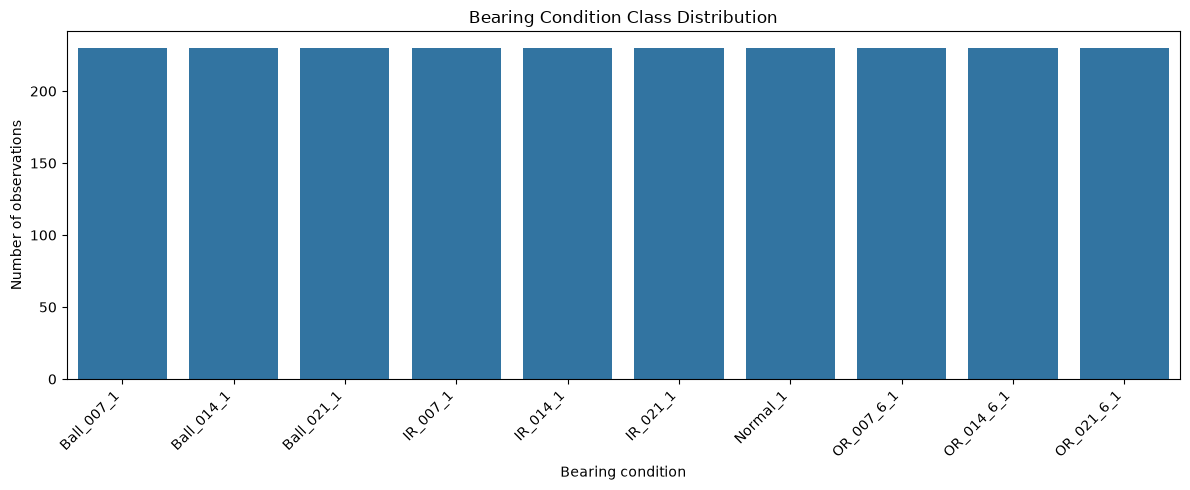

In [10]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x=TARGET_COLUMN, order=class_counts.index)
plt.title("Bearing Condition Class Distribution")
plt.xlabel("Bearing condition")
plt.ylabel("Number of observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 4. Exploratory Data Analysis (EDA)


### 4.1 Feature distributions

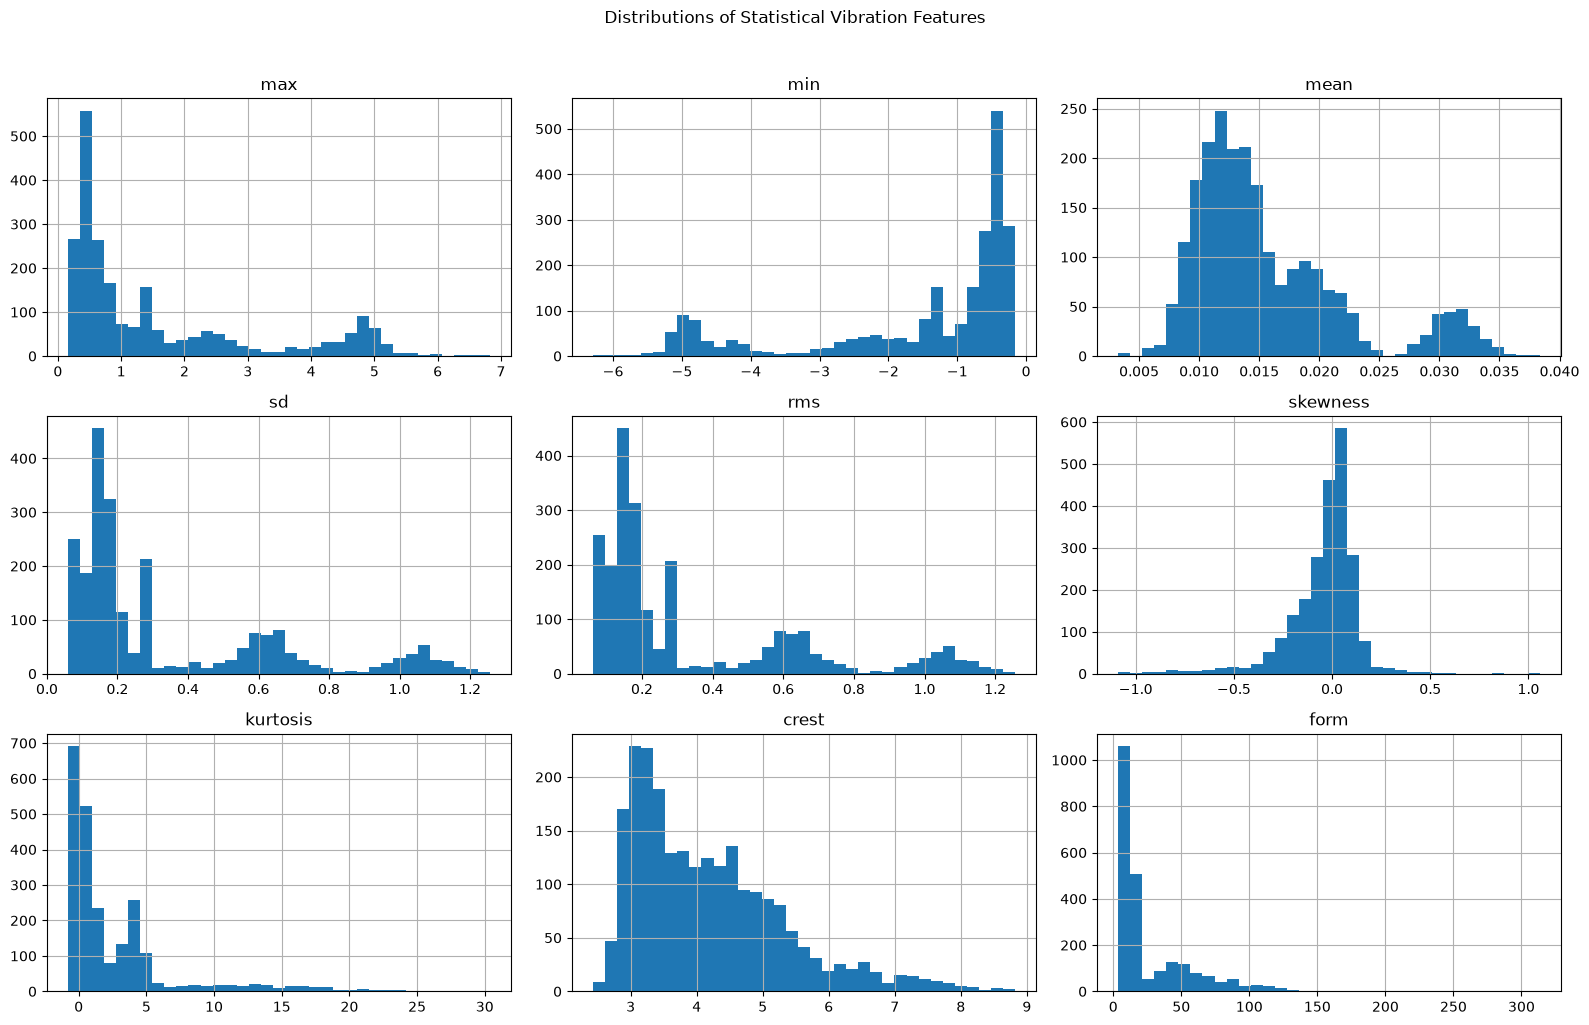

In [21]:
df[FEATURE_COLUMNS].hist(figsize=(16,10),bins=35,layout=(3,3))
plt.suptitle("Distributions of Statistical Vibration Features", y=1.02)
plt.tight_layout()
plt.show()

### 4.2 Feature comparison by fault class

Boxplots compare selected features across the ten classes. RMS and standard deviation reflect signal magnitude/energy; kurtosis and crest factor can reflect impulsive behavior. Overlap between classes is expected and is one reason to evaluate a model rather than infer separability from a plot alone.

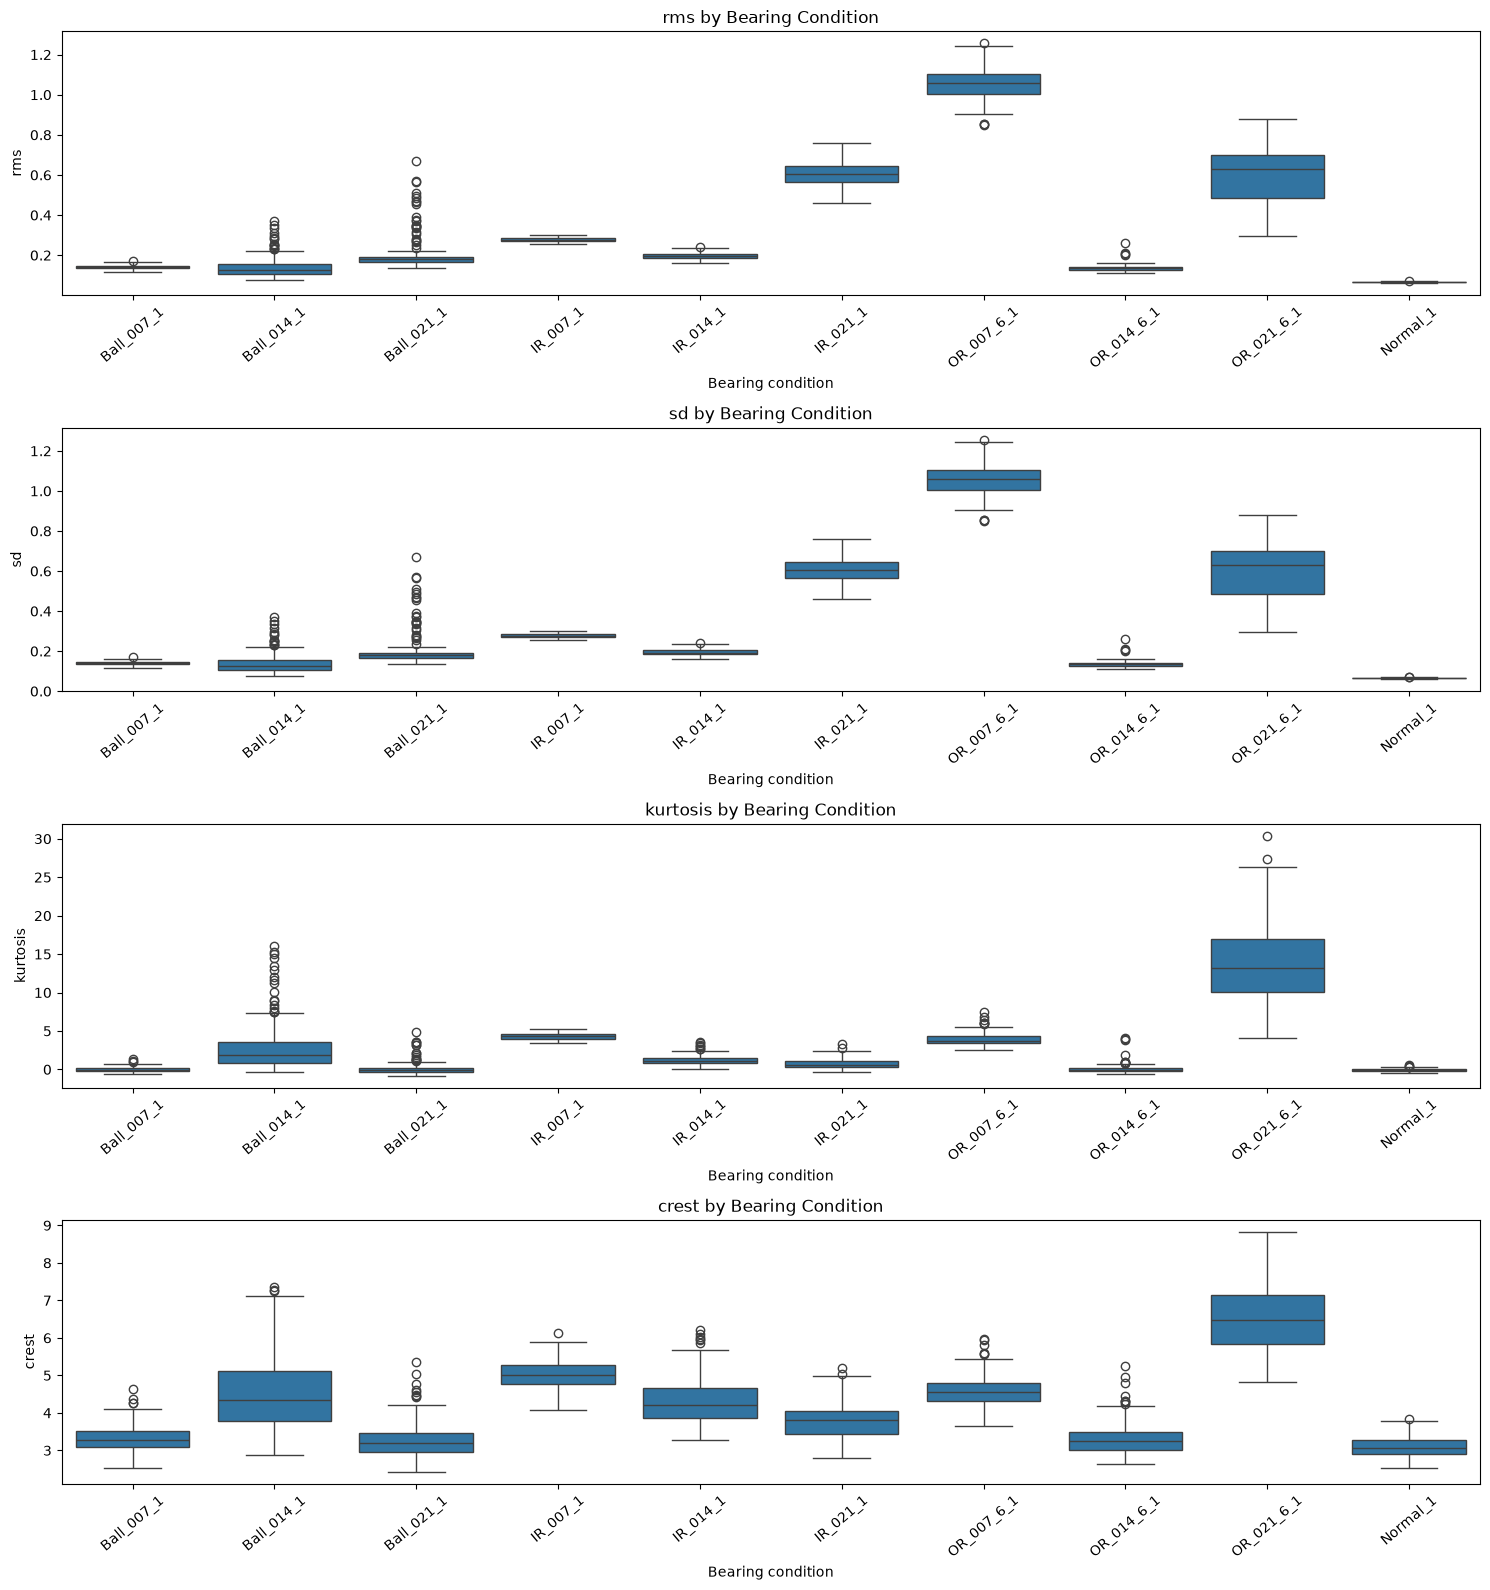

In [24]:
features_to_compare = ["rms", "sd", "kurtosis", "crest"]
fig, axes = plt.subplots(len(features_to_compare), 1, figsize=(15, 16))

for ax, feature in zip(axes, features_to_compare):
    sns.boxplot(data=df, x=TARGET_COLUMN, y=feature, ax=ax)
    ax.set_title(f"{feature} by Bearing Condition")
    ax.set_xlabel("Bearing condition")
    ax.tick_params(axis="x", rotation=40)

plt.tight_layout()
plt.show()

### 4.3 Correlation analysis

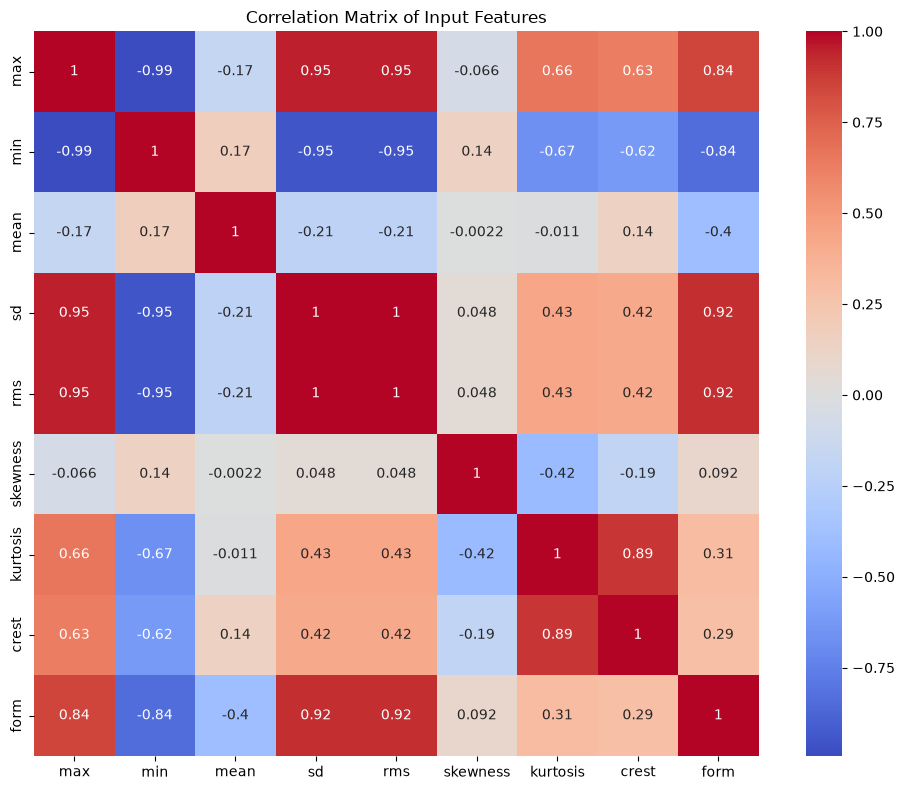

In [31]:
corr = df[FEATURE_COLUMNS].corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, square=True)
plt.title("Correlation Matrix of Input Features")
plt.tight_layout()
plt.show()


In [32]:
print(corr)

               max       min      mean        sd       rms  skewness  \
max       1.000000 -0.992793 -0.165105  0.951709  0.951700 -0.065620   
min      -0.992793  1.000000  0.171739 -0.947029 -0.947007  0.137173   
mean     -0.165105  0.171739  1.000000 -0.211367 -0.209568 -0.002229   
sd        0.951709 -0.947029 -0.211367  1.000000  0.999998  0.047614   
rms       0.951700 -0.947007 -0.209568  0.999998  1.000000  0.047715   
skewness -0.065620  0.137173 -0.002229  0.047614  0.047715  1.000000   
kurtosis  0.662241 -0.672925 -0.011141  0.432915  0.432718 -0.422060   
crest     0.633399 -0.616668  0.143599  0.419115  0.419176 -0.187349   
form      0.844366 -0.840658 -0.395792  0.920629  0.920397  0.091861   

          kurtosis     crest      form  
max       0.662241  0.633399  0.844366  
min      -0.672925 -0.616668 -0.840658  
mean     -0.011141  0.143599 -0.395792  
sd        0.432915  0.419115  0.920629  
rms       0.432718  0.419176  0.920397  
skewness -0.422060 -0.187349  0.0

### 4.4 Outlier inspection

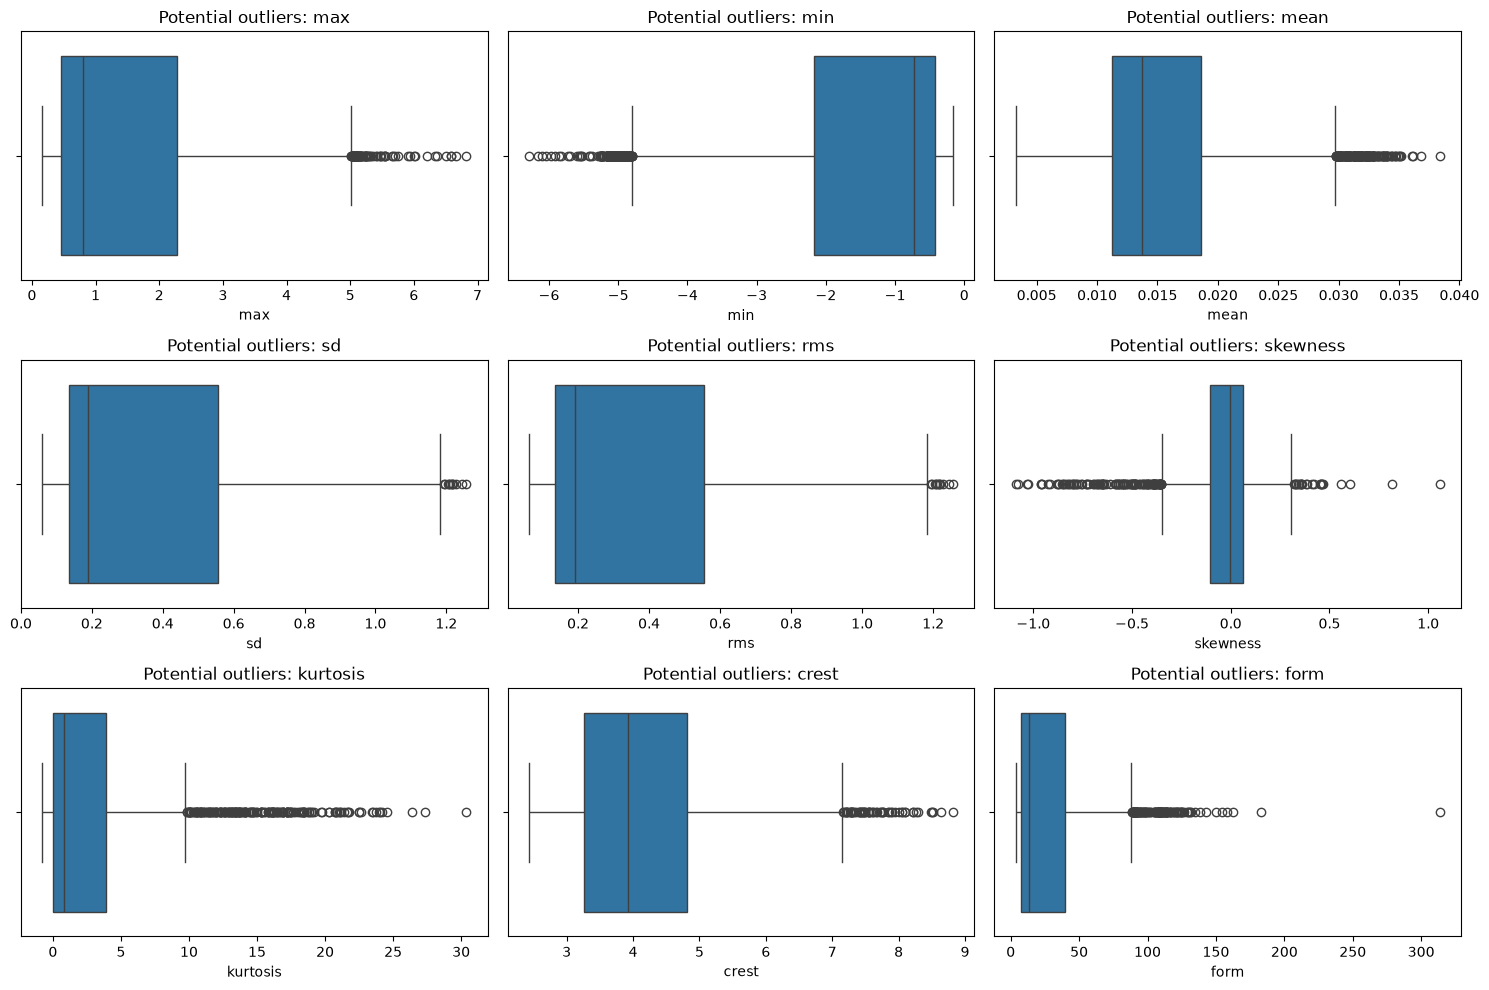

In [34]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, feature in zip(axes.flat, FEATURE_COLUMNS):
    sns.boxplot(x=df[feature], ax=ax)
    ax.set_title(f"Potential outliers: {feature}")
plt.tight_layout()
plt.show()


### 4.5 EDA Summary and Observations

The exploratory data analysis provides several important insights into the vibration dataset and the relationships between its statistical features.

#### 1. Differences between bearing conditions

The boxplots show that the statistical features have different distributions depending on the bearing condition.

**RMS and Standard Deviation**

- The `OR_007_6_1` class exhibits the highest RMS and standard deviation values, with medians around 1.05.
- `IR_021_1` and `OR_021_6_1` also exhibit relatively high vibration levels.
- `Normal_1` has the lowest RMS and standard deviation values.
- Several classes, particularly `Ball_014_1` and `Ball_021_1`, contain observations outside their main distributions.

These observations suggest that RMS and standard deviation are useful indicators of vibration intensity and can help distinguish certain fault conditions from healthy operation.

**Kurtosis**

- `OR_021_6_1` exhibits notably high kurtosis values, with a median around 13 and some observations exceeding 30.
- `IR_007_1` and `OR_007_6_1` also show relatively high kurtosis.
- `Ball_014_1` contains numerous high-value outliers.
- Healthy observations generally have kurtosis values close to zero.

Kurtosis helps describe the distribution of vibration amplitudes and its sensitivity to extreme values. High values may indicate impulsive vibration behavior associated with certain bearing faults.

**Crest Factor**

- `OR_021_6_1` exhibits the highest crest factor, with a median around 6.5.
- `IR_007_1` and `OR_007_6_1` also show relatively high values.
- `Normal_1` has comparatively low crest factor values.
- Some other fault classes contain high-value observations outside their main distributions.

This suggests that crest factor can provide additional information about peak vibration amplitudes relative to overall vibration energy.

Overall, the boxplots indicate that different bearing faults produce different statistical patterns. However, no single feature is sufficient to distinguish all ten classes reliably.

#### 2. Correlation analysis

The correlation matrix reveals several strong relationships between the numerical features.

The most significant observations are:

- `sd` and `rms` have an almost perfect positive correlation (0.999998). These features contain extremely similar linear information in this dataset.
- `max` and `sd` have a strong positive correlation (0.951709).
- `max` and `rms` also have a strong positive correlation (0.951700).
- `min` has strong negative correlations with `max` (-0.992793), `sd` (-0.947029), and `rms` (-0.947007).
- `form` is strongly correlated with `sd` (0.920629) and `rms` (0.920397).
- `kurtosis` and `crest` have a strong positive correlation (0.892333).
- `mean` has relatively weak linear correlations with most other features.
- `skewness` also has generally weak correlations with the remaining features.

These relationships indicate that some features describe overlapping characteristics of the vibration signal.

In particular, the near-perfect correlation between `sd` and `rms` suggests substantial redundancy.

#### 3. Outlier observations

The boxplots identify several observations outside the main feature distributions.

Notable examples include:

- High RMS and standard deviation observations in `Ball_014_1` and `Ball_021_1`.
- High kurtosis observations in `Ball_014_1` and `OR_021_6_1`.
- High crest factor observations across several faulty bearing classes.

These observations should not automatically be removed.

In vibration analysis, extreme values can represent meaningful changes in the signal, including impulsive behavior associated with bearing defects.

Therefore, the observations will be retained unless further investigation identifies actual measurement or data-quality errors.

#### 4. Implications for machine learning

The EDA results provide several considerations for the next stage:

1. RMS and standard deviation are potentially informative features for identifying changes in vibration intensity.
2. Kurtosis and crest factor may help identify impulsive vibration characteristics.
3. Strong correlations indicate that some features contain overlapping information.
4. Feature scaling will be necessary for the SVM model.
5. Random Forest can handle correlated features, although their importance may be distributed across related variables.

We will initially retain all nine features rather than removing correlated variables prematurely. The Random Forest and SVM models will allow us to evaluate their predictive usefulness.

#### 5. Conclusion

The exploratory analysis confirms that the dataset contains meaningful differences between bearing conditions and that its statistical features provide potentially useful information for multiclass classification.

However, the observed correlations and overlapping feature distributions indicate that classification cannot be based on a single statistical measurement.

The next stage will therefore apply preprocessing and train two machine-learning algorithms, Random Forest and Support Vector Machine, to evaluate how effectively the nine features can distinguish the ten bearing conditions.

The EDA findings are exploratory observations and do not establish that any individual feature causes a particular bearing fault.


## 5. Data preprocessing

In [36]:
X = df[FEATURE_COLUMNS].copy()
y = df[TARGET_COLUMN].astype(str).copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Missing values in X:", int(X.isna().sum().sum()))
print("Missing values in y:", int(y.isna().sum()))
print("Duplicate rows in full dataset:", int(df.duplicated().sum()))
print("Label counts:")
display(y.value_counts().sort_index())

if X.isna().any().any() or y.isna().any():
    raise ValueError("Missing values must be resolved before model training.")
if not all(pd.api.types.is_numeric_dtype(X[c]) for c in X.columns):
    raise TypeError("All input features must be numeric.")

X shape: (2300, 9)
y shape: (2300,)
Missing values in X: 0
Missing values in y: 0
Duplicate rows in full dataset: 0
Label counts:


fault
Ball_007_1    230
Ball_014_1    230
Ball_021_1    230
IR_007_1      230
IR_014_1      230
IR_021_1      230
Normal_1      230
OR_007_6_1    230
OR_014_6_1    230
OR_021_6_1    230
Name: count, dtype: int64

## 6. Training and validation strategy

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])
print("\nTrain class proportions:")
display(y_train.value_counts(normalize=True).sort_index().to_frame("proportion"))
print("\nTest class proportions:")
display(y_test.value_counts(normalize=True).sort_index().to_frame("proportion"))

Train size: 1840
Test size: 460

Train class proportions:


,proportion
fault,
Ball_007_1,0.1
Ball_014_1,0.1
Ball_021_1,0.1
IR_007_1,0.1
IR_014_1,0.1
IR_021_1,0.1
Normal_1,0.1
OR_007_6_1,0.1
OR_014_6_1,0.1



Test class proportions:


,proportion
fault,
Ball_007_1,0.1
Ball_014_1,0.1
Ball_021_1,0.1
IR_007_1,0.1
IR_014_1,0.1
IR_021_1,0.1
Normal_1,0.1
OR_007_6_1,0.1
OR_014_6_1,0.1


In [40]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)

## 7. Machine-learning model training

### 7.1 Random Forest

A decision tree repeatedly splits data using feature thresholds to make subsets more class-pure. A Random Forest trains many trees on randomized samples and feature subsets, then aggregates their predictions. This can capture nonlinear interactions in statistical vibration features and is generally robust without feature scaling.

In [41]:
rf = RandomForestClassifier(
    random_state=SEED,
    class_weight="balanced",
    n_jobs=-1
)

rf_param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [None, 12, 20],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.8],
}

rf_search = GridSearchCV(
    estimator=rf,
    param_grid=rf_param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)
rf_search.fit(X_train, y_train)

best_rf = rf_search.best_estimator_
print("Random Forest best CV macro-F1:", rf_search.best_score_)
print("Random Forest best parameters:")
display(rf_search.best_params_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Random Forest best CV macro-F1: 0.969453151126061
Random Forest best parameters:


{'max_depth': None,
 'max_features': 'sqrt',
 'min_samples_leaf': 2,
 'n_estimators': 200}

### 7.2 Support Vector Machine (SVM)
SVM finds decision boundaries that separate classes while balancing margin size and classification errors. Support vectors are training observations that help define the boundary. The RBF kernel allows nonlinear decision boundaries.

- **C** controls the penalty for training errors: larger values fit training data more strictly and can overfit.
- **gamma** controls the locality of the RBF kernel: larger values make each sample's influence more local.
- **StandardScaler** is important because features have different magnitudes.

The scaler and classifier are kept together in one pipeline.

In [42]:
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="rbf", class_weight="balanced"))
])

svm_param_grid = {
    "classifier__C": [1, 10, 100],
    "classifier__gamma": ["scale", 0.01, 0.1],
}

svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)
svm_search.fit(X_train, y_train)

best_svm = svm_search.best_estimator_
print("SVM best CV macro-F1:", svm_search.best_score_)
print("SVM best parameters:")
display(svm_search.best_params_)

Fitting 5 folds for each of 9 candidates, totalling 45 fits
SVM best CV macro-F1: 0.9649900925311711
SVM best parameters:


{'classifier__C': 100, 'classifier__gamma': 0.1}

### 7.3 Fair comparison
Both models are close to identicall regarding the score but will have to evaluate and see


## 8. Model evaluation

In [43]:
def evaluate_model(model, X_eval, y_eval, model_name):
    predictions = model.predict(X_eval)
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "Precision (macro)": precision_score(y_eval, predictions, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_eval, predictions, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_eval, predictions, average="macro", zero_division=0),
    }
    print(f"\n{model_name} classification report:")
    print(classification_report(y_eval, predictions, labels=EXPECTED_CLASSES, zero_division=0))
    return predictions, metrics

rf_test_predictions, rf_metrics = evaluate_model(best_rf, X_test, y_test, "Random Forest")
svm_test_predictions, svm_metrics = evaluate_model(best_svm, X_test, y_test, "SVM")

comparison = pd.DataFrame([rf_metrics, svm_metrics]).sort_values("F1 (macro)", ascending=False)
display(comparison)


Random Forest classification report:
              precision    recall  f1-score   support

  Ball_007_1       0.98      0.87      0.92        46
  Ball_014_1       1.00      0.89      0.94        46
  Ball_021_1       0.88      0.83      0.85        46
    IR_007_1       1.00      1.00      1.00        46
    IR_014_1       1.00      1.00      1.00        46
    IR_021_1       0.94      1.00      0.97        46
  OR_007_6_1       0.98      1.00      0.99        46
  OR_014_6_1       0.76      0.91      0.83        46
  OR_021_6_1       0.98      0.98      0.98        46
    Normal_1       1.00      1.00      1.00        46

    accuracy                           0.95       460
   macro avg       0.95      0.95      0.95       460
weighted avg       0.95      0.95      0.95       460


SVM classification report:
              precision    recall  f1-score   support

  Ball_007_1       0.93      0.87      0.90        46
  Ball_014_1       0.95      0.85      0.90        46
  Ball_021_1

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Random Forest,0.947826,0.951873,0.947826,0.948361
1,SVM,0.939130,0.943102,0.939130,0.939915


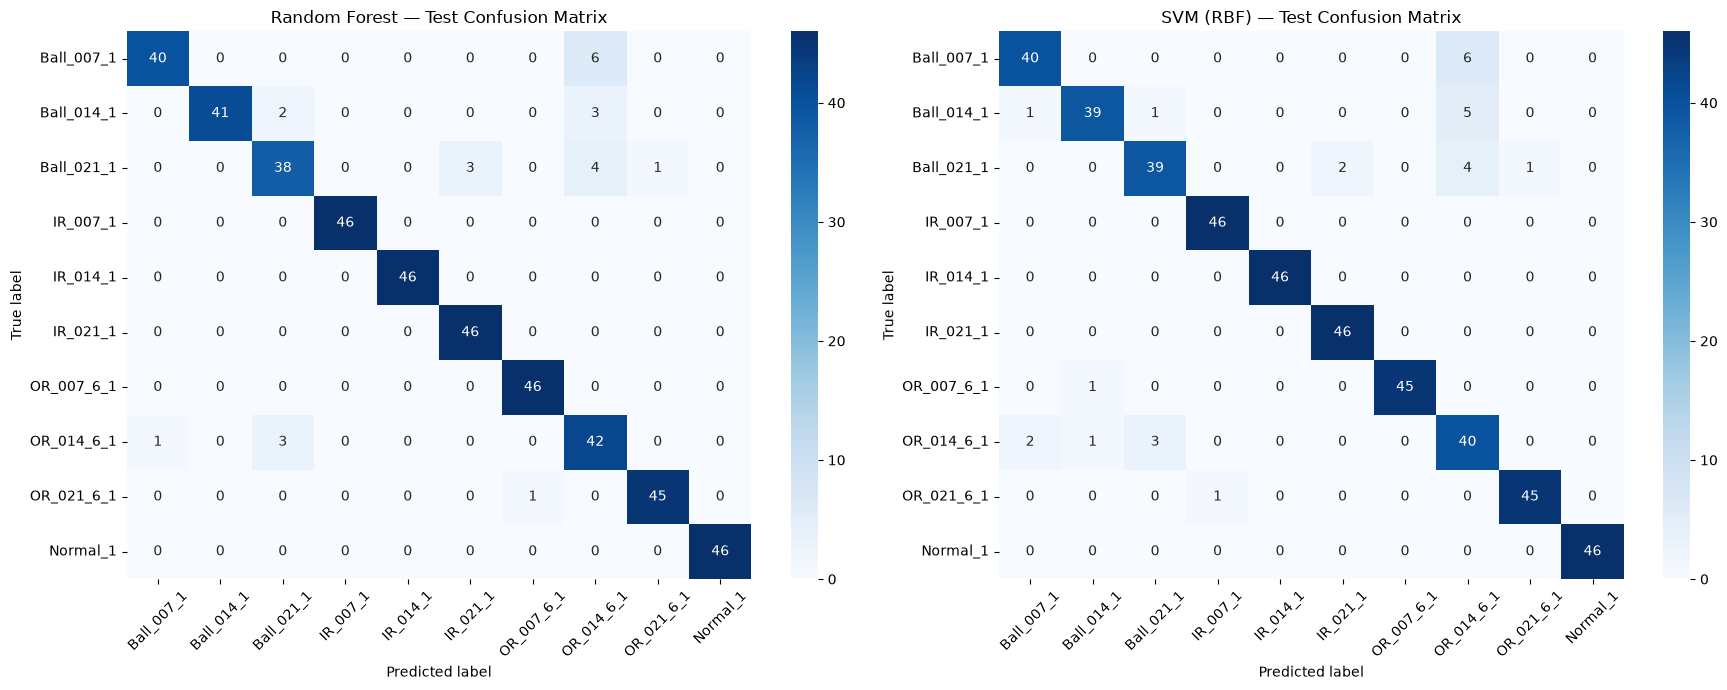

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, model_name, predictions in [
    (axes[0], "Random Forest", rf_test_predictions),
    (axes[1], "SVM (RBF)", svm_test_predictions)
]:
    cm = confusion_matrix(y_test, predictions, labels=EXPECTED_CLASSES)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=EXPECTED_CLASSES, yticklabels=EXPECTED_CLASSES, ax=ax
    )
    ax.set_title(f"{model_name} — Test Confusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

## Model Evaluation ressults

Before evaluating the models on the test set, we compare the results obtained during the training and validation process. Random Forest and Support Vector Machine (SVM) were trained using the same training data, with hyperparameter selection performed through cross-validation.

Both models are expected to be evaluated on the same unseen test partition using accuracy, precision, recall, macro F1-score, classification reports, and confusion matrices.

The **macro-average F1-score** is particularly important for this multiclass classification problem because it gives equal importance to each of the ten bearing-condition classes, rather than allowing performance on one class to dominate the overall evaluation.

In industrial predictive maintenance, recall is also important because incorrectly classifying a faulty bearing as another condition may delay fault detection and potentially lead to equipment damage or unexpected downtime.

The confusion matrices will provide a more detailed view of the classification results by identifying which bearing conditions are correctly detected and which fault categories are most frequently confused.

The test set remains separate from hyperparameter tuning and is used only for final performance evaluation.

## 9. Feature importance and interpretation

,importance
sd,0.207897
rms,0.202275
mean,0.166759
kurtosis,0.113224
min,0.085254
max,0.084283
form,0.072441
crest,0.053916
skewness,0.013951


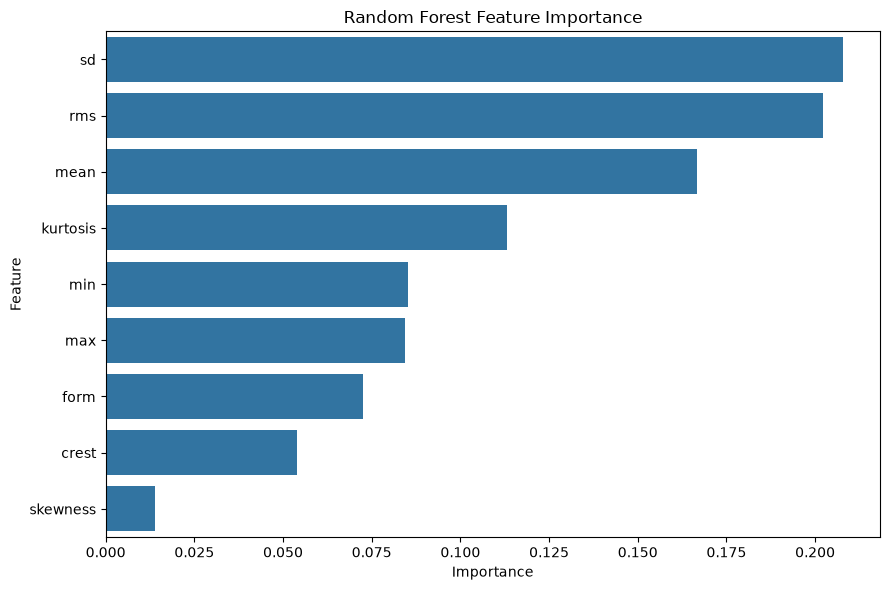

In [47]:
rf_importance = pd.Series(
    best_rf.feature_importances_,
    index=FEATURE_COLUMNS
).sort_values(ascending=False)

display(rf_importance.rename("importance").to_frame())

plt.figure(figsize=(9, 6))
sns.barplot(x=rf_importance.values, y=rf_importance.index)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

###  permutation importance on the held-out test set

,mean score decrease
mean,0.227150
kurtosis,0.156570
sd,0.069873
rms,0.059423
min,0.010322
form,0.008891
max,0.006200
crest,0.003975
skewness,0.000923


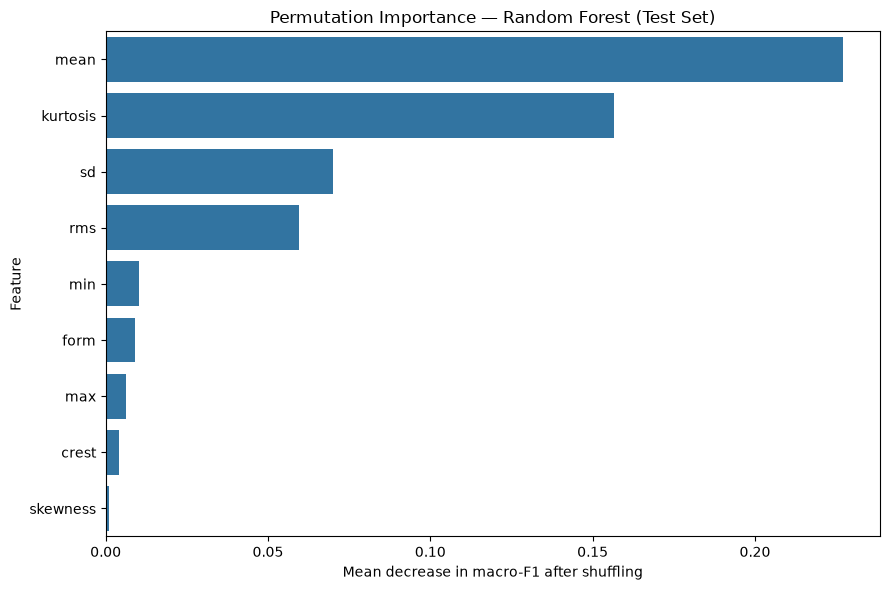

In [49]:
# Compute macro-F1 permutation importance for whichever model has the better
# training-CV macro-F1 score (selection is based on CV, not test results).
cv_scores = {
    "Random Forest": rf_search.best_score_,
    "SVM": svm_search.best_score_
}
cv_selected_name = max(cv_scores, key=cv_scores.get)
cv_selected_model = best_rf if cv_selected_name == "Random Forest" else best_svm

perm = permutation_importance(
    cv_selected_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=SEED,
    n_jobs=-1
)
perm_importance = pd.Series(
    perm.importances_mean, index=FEATURE_COLUMNS
).sort_values(ascending=False)

display(perm_importance.rename("mean score decrease").to_frame())

plt.figure(figsize=(9, 6))
sns.barplot(x=perm_importance.values, y=perm_importance.index)
plt.title(f"Permutation Importance — {cv_selected_name} (Test Set)")
plt.xlabel("Mean decrease in macro-F1 after shuffling")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 10. Final model selection and export
The selection rule is **training cross-validation macro-F1**

In [50]:
# Select the estimator using the CV macro-F1 scores only.
if rf_search.best_score_ >= svm_search.best_score_:
    final_model = best_rf
    selected_model_name = "RandomForestClassifier"
    selected_search = rf_search
    selected_cv_score = rf_search.best_score_
else:
    final_model = best_svm
    selected_model_name = "SVC_RBF_with_StandardScaler"
    selected_search = svm_search
    selected_cv_score = svm_search.best_score_

MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODEL_DIR / "model.pkl"
config_path = MODEL_DIR / "preprocessing_config.json"

dump(final_model, model_path)

config = {
    "project_name": "MotorGuard IoT",
    "dataset_filename": DATASET_FILENAME,
    "model_type": selected_model_name,
    "feature_names": FEATURE_COLUMNS,
    "target_column": TARGET_COLUMN,
    "sampling_frequency_hz": SAMPLING_FREQUENCY_HZ,
    "window_size_samples": WINDOW_SIZE_SAMPLES,
    "scaling_method": "StandardScaler inside SVM Pipeline; no scaling for Random Forest",
    "class_labels": sorted(y.unique().tolist()),
    "model_hyperparameters": selected_search.best_params_,
    "random_seed": SEED,
    "validation_strategy": {
        "holdout": "stratified 80/20 train/test split",
        "cross_validation": "5-fold StratifiedKFold on training set",
        "selection_metric": "macro F1 on training CV",
        "test_set_used_for_tuning": False
    },
    "limitations": [
        "Dataset contains no recording IDs or chronological window indices.",
        "Random split may place correlated windows from the same recording in both train and test partitions.",
        "Test results are an initial baseline and do not prove generalization to unseen physical recordings.",
        "This is bearing-condition classification, not Remaining Useful Life prediction.",
        "Dataset contains vibration statistical features only; temperature, current, and other telemetry are not included."
    ]
}

with config_path.open("w", encoding="utf-8") as f:
    json.dump(config, f, indent=4, ensure_ascii=False)

print("Selected model:", selected_model_name)
print("Training CV macro-F1:", selected_cv_score)
print("Saved model:", model_path.resolve())
print("Saved configuration:", config_path.resolve())
display(pd.Series(config, name="configuration"))

Selected model: RandomForestClassifier
Training CV macro-F1: 0.969453151126061
Saved model: C:\Users\User\Desktop\Motor\models\model.pkl
Saved configuration: C:\Users\User\Desktop\Motor\models\preprocessing_config.json


project_name                                                MotorGuard IoT
dataset_filename                          feature_time_48k_2048_load_1.csv
model_type                                          RandomForestClassifier
feature_names            [max, min, mean, sd, rms, skewness, kurtosis, ...
target_column                                                        fault
sampling_frequency_hz                                                48000
window_size_samples                                                   2048
scaling_method           StandardScaler inside SVM Pipeline; no scaling...
class_labels             [Ball_007_1, Ball_014_1, Ball_021_1, IR_007_1,...
model_hyperparameters    {'max_depth': None, 'max_features': 'sqrt', 'm...
random_seed                                                             42
validation_strategy      {'holdout': 'stratified 80/20 train/test split...
limitations              [Dataset contains no recording IDs or chronolo...
Name: configuration, dtyp

### 10.1 Reload and demonstrate predictions

In [51]:
loaded_model = load(model_path)

demo_X = X_test.iloc[:10].copy()
demo_y = y_test.iloc[:10].copy()
demo_predictions = loaded_model.predict(demo_X)

demo_results = pd.DataFrame({
    "actual": demo_y.values,
    "predicted": demo_predictions,
    "correct": demo_y.values == demo_predictions
}, index=demo_X.index)

display(demo_results)

observed_prediction_labels = set(pd.Series(demo_predictions).astype(str).unique())
allowed_labels = set(EXPECTED_CLASSES)
print("Prediction labels observed in demonstration:", sorted(observed_prediction_labels))
print("All predictions are among expected labels:", observed_prediction_labels.issubset(allowed_labels))

,actual,predicted,correct
1071,IR_014_1,IR_014_1,True
2259,Normal_1,Normal_1,True
116,Ball_007_1,Ball_007_1,True
2081,Normal_1,Normal_1,True
528,Ball_021_1,Ball_021_1,True
2102,Normal_1,Normal_1,True
271,Ball_014_1,Ball_014_1,True
231,Ball_014_1,Ball_014_1,True
1975,OR_021_6_1,OR_021_6_1,True
1301,IR_021_1,IR_021_1,True


Prediction labels observed in demonstration: ['Ball_007_1', 'Ball_014_1', 'Ball_021_1', 'IR_014_1', 'IR_021_1', 'Normal_1', 'OR_021_6_1']
All predictions are among expected labels: True
